In [1]:
# Imports, row-wise feature engineering, and train/test split
# This cell replaces the earlier all-data preprocessing setup.
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import VarianceThreshold
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from scipy.stats import randint, uniform, loguniform
import xgboost as xgb

# Reload the source data so earlier full-data imputing/encoding does not leak
# into this train/test evaluation.
df_model = pd.read_csv("car details v4.csv")

# These are row-wise transformations; they do not learn dataset-wide values.
for col in ["Engine", "Max Power", "Max Torque"]:
    df_model[col] = pd.to_numeric(
        df_model[col].astype("string").str.extract(r"([0-9]+(?:\.[0-9]+)?)", expand=False),
        errors="coerce",
    )

df_model["Car_Age"] = 2022 - df_model["Year"]
dimensions = ["Length", "Width", "Height"]
df_model["Size"] = df_model[dimensions].prod(axis=1, min_count=3)
df_model = df_model.drop(columns=dimensions)

X = df_model.drop(columns="Price")
y = df_model["Price"]

# Hold out the test set before fitting any learned preprocessing.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

categorical_cols = X.select_dtypes(
    include=["object", "string", "category"]
).columns.tolist()
numeric_cols = X.select_dtypes(include="number").columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", SimpleImputer(strategy="median"), numeric_cols),
        (
            "categorical",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("encoder", OneHotEncoder(handle_unknown="ignore")),
            ]),
            categorical_cols,
        ),
    ],
    remainder="drop",
)


In [2]:
# Tune XGBoost using cross-validation on the training split only.
# The test split is used once, after model selection, for final evaluation.
xgb_pipeline = Pipeline([
    ("preprocessing", preprocessor),
    ("feature_selection", VarianceThreshold(threshold=0.01)),
    ("regressor", xgb.XGBRegressor(
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1,
        verbosity=0,
        tree_method="hist",
    )),
])

param_distributions = {
    "regressor__n_estimators": randint(250, 801),
    "regressor__max_depth": randint(3, 8),
    "regressor__learning_rate": loguniform(0.025, 0.18),
    "regressor__subsample": uniform(0.7, 0.3),
    "regressor__colsample_bytree": uniform(0.65, 0.35),
    "regressor__min_child_weight": randint(1, 9),
    "regressor__reg_alpha": loguniform(0.001, 2.0),
    "regressor__reg_lambda": loguniform(0.5, 15.0),
    "regressor__gamma": uniform(0.0, 0.5),
}

search = RandomizedSearchCV(
    estimator=xgb_pipeline,
    param_distributions=param_distributions,
    n_iter=20,
    scoring="neg_mean_absolute_error",
    cv=3,
    random_state=42,
    n_jobs=1,
    verbose=1,
)
search.fit(X_train, y_train)

xgb_model = search.best_estimator_
print(f"Best 3-fold CV MAE: {-search.best_score_:,.2f}")
print("Best parameters:", search.best_params_)

# Final evaluation on the held-out test set
y_pred_train_xgb = xgb_model.predict(X_train)
y_pred_test_xgb = xgb_model.predict(X_test)

train_mae_xgb = mean_absolute_error(y_train, y_pred_train_xgb)
test_mae_xgb = mean_absolute_error(y_test, y_pred_test_xgb)
train_rmse_xgb = np.sqrt(mean_squared_error(y_train, y_pred_train_xgb))
test_rmse_xgb = np.sqrt(mean_squared_error(y_test, y_pred_test_xgb))
train_r2_xgb = r2_score(y_train, y_pred_train_xgb)
test_r2_xgb = r2_score(y_test, y_pred_test_xgb)

print("\nTuned XGBoost Results:")
print(f"Train MAE:  {train_mae_xgb:,.2f}")
print(f"Test MAE:   {test_mae_xgb:,.2f}")
print(f"Train RMSE: {train_rmse_xgb:,.2f}")
print(f"Test RMSE:  {test_rmse_xgb:,.2f}")
print(f"Train R²:   {train_r2_xgb:.4f}")
print(f"Test R²:    {test_r2_xgb:.4f}")


Fitting 3 folds for each of 20 candidates, totalling 60 fits
Best 3-fold CV MAE: 307,091.30
Best parameters: {'regressor__colsample_bytree': np.float64(0.8624619866903397), 'regressor__gamma': np.float64(0.13799959101127168), 'regressor__learning_rate': np.float64(0.044868847349544064), 'regressor__max_depth': 7, 'regressor__min_child_weight': 1, 'regressor__n_estimators': 770, 'regressor__reg_alpha': np.float64(0.3541629671265133), 'regressor__reg_lambda': np.float64(0.9828724483023061), 'regressor__subsample': np.float64(0.7016566351370807)}

Tuned XGBoost Results:
Train MAE:  22,181.05
Test MAE:   270,126.84
Train RMSE: 42,087.71
Test RMSE:  931,359.07
Train R²:   0.9997
Test R²:    0.8758


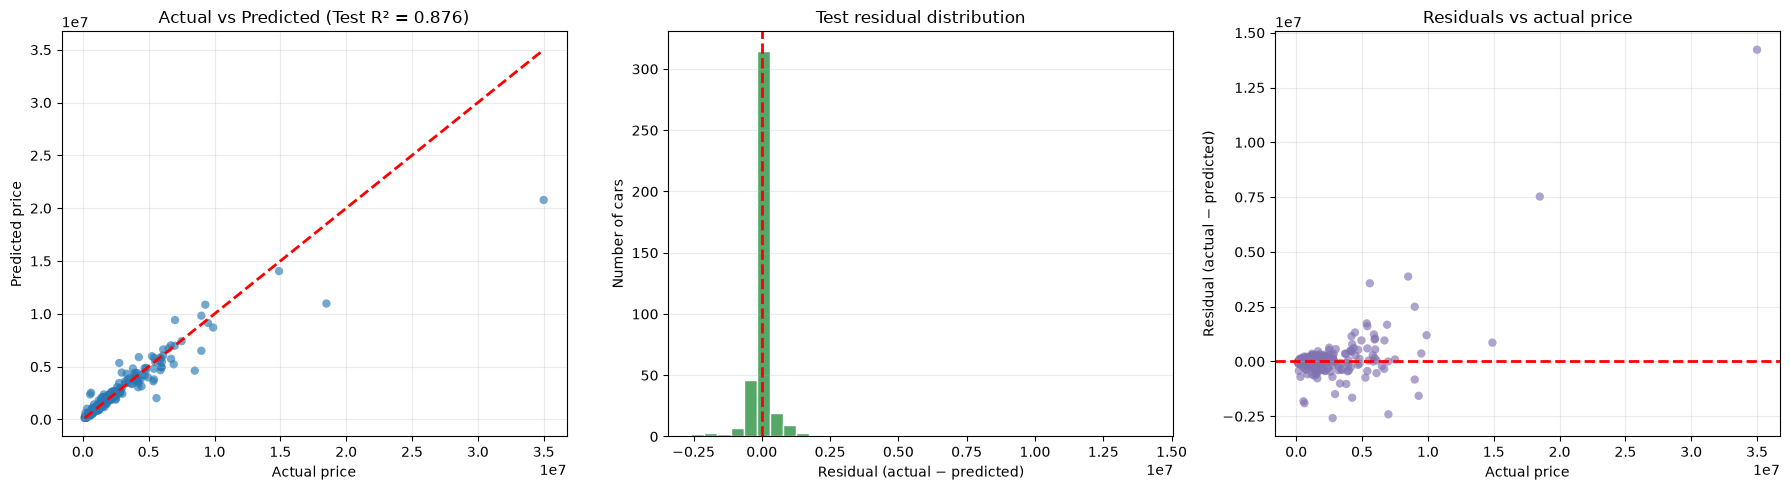

In [3]:
import matplotlib.pyplot as plt

# Visualize held-out test predictions and errors
residuals = y_test.to_numpy() - y_pred_test_xgb
price_min = min(y_test.min(), y_pred_test_xgb.min())
price_max = max(y_test.max(), y_pred_test_xgb.max())

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Actual vs predicted prices; points close to the diagonal are more accurate.
axes[0].scatter(y_test, y_pred_test_xgb, alpha=0.65, color="#2878B5", edgecolors="none")
axes[0].plot([price_min, price_max], [price_min, price_max], "r--", linewidth=2)
axes[0].set_title(f"Actual vs Predicted (Test R² = {test_r2_xgb:.3f})")
axes[0].set_xlabel("Actual price")
axes[0].set_ylabel("Predicted price")
axes[0].grid(alpha=0.25)

# Residuals are actual price minus predicted price.
axes[1].hist(residuals, bins=35, color="#55A868", edgecolor="white")
axes[1].axvline(0, color="red", linestyle="--", linewidth=2)
axes[1].set_title("Test residual distribution")
axes[1].set_xlabel("Residual (actual − predicted)")
axes[1].set_ylabel("Number of cars")
axes[1].grid(axis="y", alpha=0.25)

# A pattern or widening spread can reveal systematic error or larger errors at high prices.
axes[2].scatter(y_test, residuals, alpha=0.65, color="#8172B2", edgecolors="none")
axes[2].axhline(0, color="red", linestyle="--", linewidth=2)
axes[2].set_title("Residuals vs actual price")
axes[2].set_xlabel("Actual price")
axes[2].set_ylabel("Residual (actual − predicted)")
axes[2].grid(alpha=0.25)

plt.tight_layout()
plt.show()
